In [3]:
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_google_genai import GoogleGenerativeAIEmbeddings

import os
from dotenv import load_dotenv

# API KEY
load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")

# Cargar datos
loader = PyPDFDirectoryLoader("files")
documents = loader.load()
print(f"Páginas cargadas: {len(documents)}")

# Separar en chunks
text_splitter = RecursiveCharacterTextSplitter(
  chunk_size=500,
  chunk_overlap=50
)
docs_split = text_splitter.split_documents(documents)
print(f"Total de fragmentos (chunks) generados: {len(docs_split)}")

# Enbeddings
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

C:\Users\matia\AppData\Local\Temp\ipykernel_34484\2171809266.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFDirectoryLoader


Páginas cargadas: 108
Total de fragmentos (chunks) generados: 317


In [ ]:
# OJO NO CORRER ESTA CELDA PORQUE YA ESTA CREADO EL CHROMA

from langchain_chroma import Chroma
import time

# Crear colección Chroma vacía
vectorstore_chroma = Chroma(
    collection_name="smn_documentos",
    embedding_function=embeddings,
    persist_directory="./chroma_db_smn"
)

# Procesar documentos en lotes para no superar
# el límite de solicitudes de Gemini
batch_size = 75

total = len(docs_split)

for i in range(0, total, batch_size):
    lote = docs_split[i:i + batch_size]

    print(
        f"Procesando lote {i // batch_size + 1}: "
        f"documentos {i + 1} a {min(i + batch_size, total)}"
    )

    vectorstore_chroma.add_documents(lote)

    print(
        f"Documentos guardados hasta ahora: "
        f"{vectorstore_chroma._collection.count()}"
    )

    # Esperar antes del siguiente lote
    if i + batch_size < total:
        print("Esperando 60 segundos para respetar la cuota...\n")
        time.sleep(60)

print("\nBase Chroma creada correctamente.")
print(
    "Total de documentos almacenados:",
    vectorstore_chroma._collection.count()
)

Procesando lote 1: documentos 1 a 75
Documentos guardados hasta ahora: 75
Esperando 60 segundos para respetar la cuota...

Procesando lote 2: documentos 76 a 150
Documentos guardados hasta ahora: 150
Esperando 60 segundos para respetar la cuota...

Procesando lote 3: documentos 151 a 225
Documentos guardados hasta ahora: 225
Esperando 60 segundos para respetar la cuota...

Procesando lote 4: documentos 226 a 300
Documentos guardados hasta ahora: 300
Esperando 60 segundos para respetar la cuota...

Procesando lote 5: documentos 301 a 317
Documentos guardados hasta ahora: 317

Base Chroma creada correctamente.
Total de documentos almacenados: 317


In [ ]:
# Cargar la base vectorial Chroma ya existente
from langchain_chroma import Chroma

vectorstore = Chroma(
    collection_name="smn_documentos",
    embedding_function=embeddings,
    persist_directory="./chroma_db_smn"
)

print(
    "Documentos cargados desde Chroma:",
    vectorstore._collection.count()
)

# Crear retriever
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 5}
)

Documentos cargados desde Chroma: 317


In [ ]:
# Cargar dataset de temperaturas previamente limpiado
import pandas as pd

df = pd.read_csv(
    "datasets/temperaturas_365d.csv",
    parse_dates=["fecha"]
)

# Limpieza mínima de seguridad
df["estacion"] = df["estacion"].str.strip()

df = df.sort_values(
    by=["estacion", "fecha"]
).reset_index(drop=True)

# Verificaciones
print("Cantidad de registros:", len(df))

print("\nRango de fechas:")
print("Desde:", df["fecha"].min())
print("Hasta:", df["fecha"].max())

print("\nValores faltantes:")
print(df.isna().sum())

display(df.head())

Cantidad de registros: 42949

Rango de fechas:
Desde: 2025-08-27 00:00:00
Hasta: 2026-08-26 00:00:00

Valores faltantes:
fecha          0
tmax        2019
tmin         552
estacion       0
dtype: int64


,fecha,tmax,tmin,estacion
0,2025-08-27,20.0,12.0,AEROPARQUE AERO
1,2025-08-28,18.4,12.5,AEROPARQUE AERO
2,2025-08-29,20.3,14.3,AEROPARQUE AERO
3,2025-08-30,21.1,14.9,AEROPARQUE AERO
4,2025-08-31,18.1,15.1,AEROPARQUE AERO


In [ ]:
# Cargar dataset de estadísticas normales climatológicas 1991-2020
df_normales = pd.read_csv(
    "datasets/estadisticas_normales_1991-2020.csv"
)

# Limpiar espacios por seguridad
df_normales["estacion"] = df_normales["estacion"].str.strip()
df_normales["valor"] = df_normales["valor"].str.strip()

print("Cantidad de registros de normales:", len(df_normales))
print("Cantidad de estaciones:", df_normales["estacion"].nunique())

display(df_normales.head())

Cantidad de registros de normales: 784
Cantidad de estaciones: 98


,estacion,valor,enero,febrero,marzo,abril,mayo,junio,julio,agosto,septiembre,octubre,noviembre,diciembre
0,LA QUIACA OBSERVATORIO,Temperatura (°C),13.2,13.0,12.8,11.3,7.3,4.8,4.5,7.0,10.0,12.4,13.4,13.9
1,LA QUIACA OBSERVATORIO,Temperatura máxima (°C),20.6,20.4,20.6,20.3,17.8,16.3,16.1,18.0,20.0,21.7,22.5,22.2
2,LA QUIACA OBSERVATORIO,Temperatura mínima (°C),7.7,7.6,6.6,3.1,-2.5,-5.7,-6.2,-4.0,-0.4,3.3,5.5,7.3
3,LA QUIACA OBSERVATORIO,Humedad relativa (%),62.6,63.2,60.3,46.0,32.6,27.4,25.7,26.7,32.1,42.4,48.6,55.8
4,LA QUIACA OBSERVATORIO,Velocidad del Viento (km/h),6.5,6.8,6.7,5.5,4.8,5.5,5.9,6.7,7.9,7.9,7.7,7.1


In [ ]:
# Verificación de la estación "ROSARIO AERO" en el dataset de normales
display(
    df_normales[
        df_normales["estacion"] == "ROSARIO AERO"
    ]
)

,estacion,valor,enero,febrero,marzo,abril,mayo,junio,julio,agosto,septiembre,octubre,noviembre,diciembre
360,ROSARIO AERO,Temperatura (°C),24.8,23.4,21.5,17.7,14.2,11.0,10.1,12.3,15.0,18.2,21.3,23.6
361,ROSARIO AERO,Temperatura máxima (°C),30.9,29.4,27.7,23.9,20.1,17.0,16.5,19.2,21.5,24.3,27.5,29.8
362,ROSARIO AERO,Temperatura mínima (°C),18.7,17.7,16.0,12.4,9.4,6.2,4.9,6.3,8.7,12.3,15.0,17.3
363,ROSARIO AERO,Humedad relativa (%),67.8,72.8,75.4,78.1,81.0,80.9,77.9,72.6,68.5,69.3,65.6,65.5
364,ROSARIO AERO,Velocidad del Viento (km/h),12.4,11.4,10.5,10.7,10.7,10.6,11.6,12.8,14.4,15.3,14.6,12.7
365,ROSARIO AERO,Nubosidad total (octavos),3.2,3.3,3.1,3.6,4.0,4.2,3.9,3.5,3.6,3.9,3.4,3.3
366,ROSARIO AERO,Precipitación (mm),120.7,127.4,138.4,119.9,57.7,28.3,23.0,35.3,48.0,118.7,108.2,127.9
367,ROSARIO AERO,Frecuencia de días con Precipitación superior ...,6.4,6.6,6.3,6.9,4.2,2.7,2.6,2.8,4.1,7.9,6.7,7.7


In [ ]:
# Crear herramienta para buscar información en los PDF
from langchain_core.tools import tool

@tool
def buscar_informacion_texto(query: str) -> str:
  """Útil para buscar explicaciones conceptuales, definiciones técnicas o informes climáticos en los documentos PDF."""
  results = retriever.invoke(query)
  
  if not results:
    return "No se encontró información relevante en los informes."

  # Formatear la respuesta incluyendo fuente y página
  respuesta = []
  for doc in results:
    fuente = doc.metadata.get("source", "PDF desconocido")
    pagina = doc.metadata.get("page", 0) + 1
    respuesta.append(f"--- [Fuente: {fuente} (Pág. {pagina})] ---\n{doc.page_content}")
  
  return "\n\n".join(respuesta)

In [ ]:
## Ejemplo de uso de la herramienta
resultado_rag = buscar_informacion_texto.invoke({
    "query": "¿Cómo fueron las precipitaciones durante mayo de 2026?"
})

print(resultado_rag)

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 5)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
2
SMN
CARACTERÍSTICAS CLIMÁTICAS 
1 - PRECIPITACIÓN
1.1 - Precipitación media
Durante el mes de mayo, una extensa zona del país que comprende al Noroeste Argentino (NOA), 
Cuyo, centro y zona central de la Patagonia presentó precipitaciones inferiores a 20 mm (Figura 1- 
isolínea negra). En varias localidades no se registraron precipitaciones, por ejemplo: La Quiaca, Ceres,

--- [Fuente: files\Clim-Otoño 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Otoño  2026  - Vol. XXXVIII
6
SMN
FIG. 3 – Desvío de la precipitación con respecto a la normal 
1991-2020 (mm) de marzo, abril y mayo de 2026.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 9)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
6
SMN
FIG. 5 – Frecuencia de días con lluvia.
FIG. 6 – Frecuencia de días con lluvia de primera, 
segunda y tercera década.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 8)] ---
del territorio 

In [ ]:
# Crear herramienta para graficar temperaturas de una estación
from langchain_core.tools import tool
import matplotlib.pyplot as plt
from typing import Optional

@tool
def graficar_temperatura_estacion(
    estacion: str,
    fecha_inicio: str,
    fecha_fin: str
) -> str:
    """
    Genera un gráfico de temperatura máxima y mínima para una estación
    meteorológica del SMN dentro de un rango de fechas.

    Args:
        estacion: Nombre de la estación, por ejemplo "ROSARIO AERO".
        fecha_inicio: Fecha inicial en formato YYYY-MM-DD.
        fecha_fin: Fecha final en formato YYYY-MM-DD.
    """

    # Convertir las fechas recibidas a datetime
    inicio = pd.to_datetime(fecha_inicio, errors="coerce")
    fin = pd.to_datetime(fecha_fin, errors="coerce")

    if pd.isna(inicio) or pd.isna(fin):
        return "Las fechas deben tener formato YYYY-MM-DD."

    if inicio > fin:
        return "La fecha de inicio no puede ser posterior a la fecha de fin."

    # Buscar la estación ignorando mayúsculas/minúsculas
    nombre_buscado = estacion.strip().upper()

    estaciones = df["estacion"].dropna().unique()

    coincidencias = [
        e for e in estaciones
        if nombre_buscado in e.upper()
    ]

    if len(coincidencias) == 0:
        return f"No se encontró ninguna estación que coincida con '{estacion}'."

    # Si encuentra varias estaciones, pedir una más específica
    if len(coincidencias) > 1:
        opciones = ", ".join(coincidencias[:10])
        return (
            f"Se encontraron varias estaciones para '{estacion}': "
            f"{opciones}. Indicá una estación más específica."
        )

    estacion_encontrada = coincidencias[0]

    # Filtrar estación y rango de fechas
    datos = df[
        (df["estacion"] == estacion_encontrada) &
        (df["fecha"] >= inicio) &
        (df["fecha"] <= fin)
    ].copy()

    if datos.empty:
        return (
            f"No hay datos para {estacion_encontrada} "
            f"entre {fecha_inicio} y {fecha_fin}."
        )

    # Crear gráfico
    plt.figure(figsize=(12, 6))

    plt.plot(
        datos["fecha"],
        datos["tmax"],
        label="Temperatura máxima"
    )

    plt.plot(
        datos["fecha"],
        datos["tmin"],
        label="Temperatura mínima"
    )

    plt.xlabel("Fecha")
    plt.ylabel("Temperatura (°C)")
    plt.title(
        f"Temperaturas en {estacion_encontrada}\n"
        f"{fecha_inicio} a {fecha_fin}"
    )

    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()

    nombre_archivo = "grafico_temperatura.png"
    plt.savefig(nombre_archivo)
    plt.show()
    plt.close()

    return (
        f"Gráfico generado correctamente para {estacion_encontrada}. "
        f"Se utilizaron {len(datos)} registros entre "
        f"{fecha_inicio} y {fecha_fin}."
    )

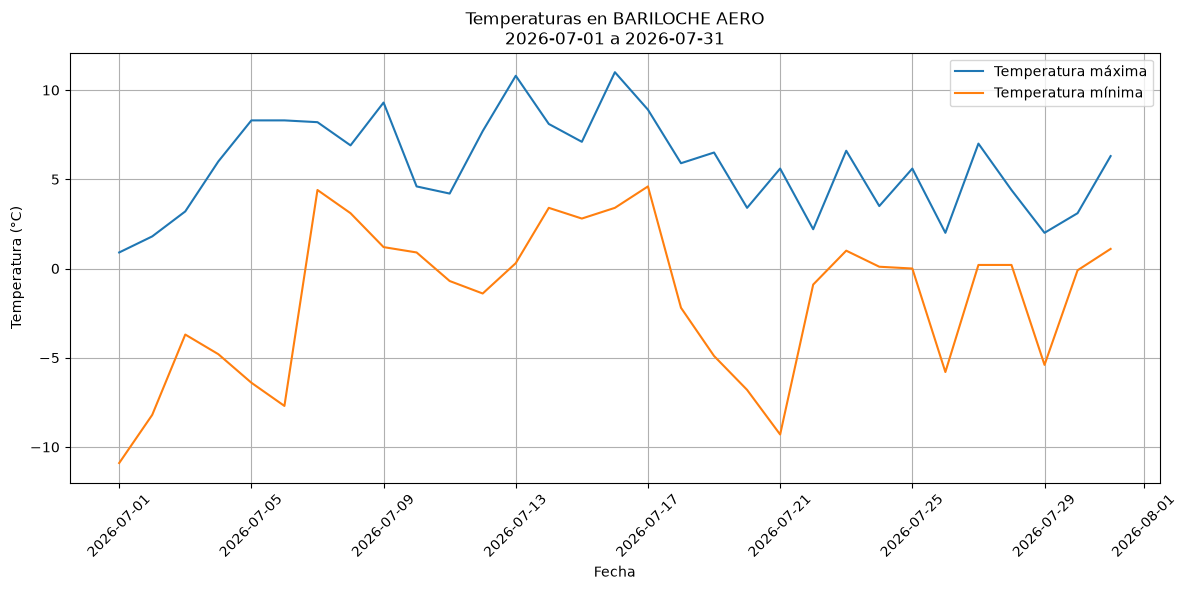

Gráfico generado correctamente para BARILOCHE AERO. Se utilizaron 31 registros entre 2026-07-01 y 2026-07-31.


In [ ]:
# PRUEBA DE LA HERRAMIENTA DE GRAFICAR TEMPERATURA

resultado = graficar_temperatura_estacion.invoke({
    "estacion": "BARILOCHE AERO",
    "fecha_inicio": "2026-07-01",
    "fecha_fin": "2026-07-31"
})

print(resultado)

In [ ]:
# Crear herramienta para comparar temperatura con normal climatológica
@tool
def comparar_temperatura_con_normal(
    estacion: str,
    mes: str,
    anio: int,
    tipo_temperatura: str
) -> str:
    """
    Compara la temperatura observada de una estación del SMN durante un mes
    con la normal climatológica 1991-2020.

    Args:
        estacion: Nombre de la estación, por ejemplo "ROSARIO AERO".
        mes: Mes en español, por ejemplo "julio".
        anio: Año a analizar, por ejemplo 2026.
        tipo_temperatura: Debe ser "maxima" o "minima".
    """

    # Normalizar parámetros recibidos
    estacion_buscada = estacion.strip().upper()
    mes = mes.strip().lower()
    tipo_temperatura = tipo_temperatura.strip().lower()

    meses = {
        "enero": 1,
        "febrero": 2,
        "marzo": 3,
        "abril": 4,
        "mayo": 5,
        "junio": 6,
        "julio": 7,
        "agosto": 8,
        "septiembre": 9,
        "octubre": 10,
        "noviembre": 11,
        "diciembre": 12
    }

    if mes not in meses:
        return f"Mes inválido: {mes}."

    # Definir qué columnas utilizar según máxima o mínima
    if tipo_temperatura in ["maxima", "máxima"]:
        columna_observada = "tmax"
        variable_normal = "Temperatura máxima (°C)"
        nombre_tipo = "máxima"

    elif tipo_temperatura in ["minima", "mínima"]:
        columna_observada = "tmin"
        variable_normal = "Temperatura mínima (°C)"
        nombre_tipo = "mínima"

    else:
        return "El tipo de temperatura debe ser 'maxima' o 'minima'."

    # Buscar coincidencias de estación en los datos diarios
    estaciones = df["estacion"].dropna().unique()

    coincidencias = [
        e for e in estaciones
        if estacion_buscada in e.upper()
    ]

    if len(coincidencias) == 0:
        return f"No se encontró la estación '{estacion}'."

    if len(coincidencias) > 1:
        opciones = ", ".join(coincidencias[:10])
        return (
            f"Se encontraron varias estaciones para '{estacion}': "
            f"{opciones}. Indicá una estación más específica."
        )

    estacion_encontrada = coincidencias[0]

    # Filtrar registros del mes y año solicitados
    numero_mes = meses[mes]

    datos_mes = df[
        (df["estacion"] == estacion_encontrada) &
        (df["fecha"].dt.year == anio) &
        (df["fecha"].dt.month == numero_mes)
    ]

    if datos_mes.empty:
        return (
            f"No hay datos observados para {estacion_encontrada} "
            f"durante {mes} de {anio}."
        )

    # Calcular promedio observado
    promedio_observado = datos_mes[columna_observada].mean()

    if pd.isna(promedio_observado):
        return (
            f"No hay suficientes mediciones de temperatura {nombre_tipo} "
            f"para {estacion_encontrada} durante {mes} de {anio}."
        )

    # Buscar normal climatológica 1991-2020
    normal = df_normales[
        (df_normales["estacion"].str.upper() == estacion_encontrada.upper()) &
        (df_normales["valor"] == variable_normal)
    ]

    if normal.empty:
        return (
            f"No se encontró la normal climatológica de temperatura "
            f"{nombre_tipo} para {estacion_encontrada}."
        )

    valor_normal = pd.to_numeric(
        normal.iloc[0][mes],
        errors="coerce"
    )

    if pd.isna(valor_normal):
        return (
            f"No existe un valor normal disponible para "
            f"{estacion_encontrada} en {mes}."
        )

    # Calcular diferencia
    diferencia = promedio_observado - valor_normal

    # Generar gráfico
    plt.figure(figsize=(7, 5))

    plt.bar(
        [f"{mes.capitalize()} {anio}", "Normal 1991-2020"],
        [promedio_observado, valor_normal]
    )

    plt.ylabel("Temperatura (°C)")
    plt.title(
        f"Temperatura {nombre_tipo} - {estacion_encontrada}\n"
        f"{mes.capitalize()} {anio} vs. normal climatológica"
    )

    plt.tight_layout()

    nombre_archivo = "comparacion_temperatura_normal.png"
    plt.savefig(nombre_archivo)
    plt.show()
    plt.close()

    # Interpretación sencilla
    if diferencia > 0:
        comparacion = "por encima"
    elif diferencia < 0:
        comparacion = "por debajo"
    else:
        comparacion = "igual"

    return (
        f"En {estacion_encontrada}, la temperatura {nombre_tipo} promedio "
        f"observada durante {mes} de {anio} fue de "
        f"{promedio_observado:.1f} °C. "
        f"La normal climatológica 1991-2020 para ese mes es "
        f"{valor_normal:.1f} °C. "
        f"La diferencia fue de {diferencia:+.1f} °C, "
        f"por lo que estuvo {comparacion} de lo normal."
    )

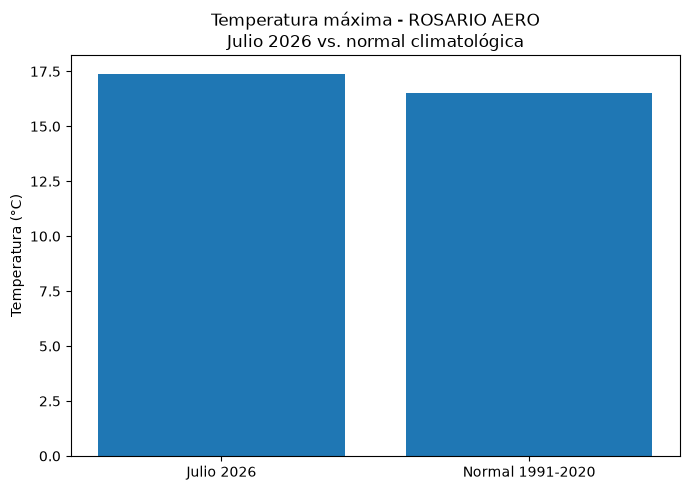

En ROSARIO AERO, la temperatura máxima promedio observada durante julio de 2026 fue de 17.4 °C. La normal climatológica 1991-2020 para ese mes es 16.5 °C. La diferencia fue de +0.9 °C, por lo que estuvo por encima de lo normal.


In [ ]:
# PRUEBA DE LA HERRAMIENTA DE COMPARACIÓN DE TEMPERATURA CON NORMAL CLIMATOLÓGICA
resultado_comparacion = comparar_temperatura_con_normal.invoke({
    "estacion": "ROSARIO AERO",
    "mes": "julio",
    "anio": 2026,
    "tipo_temperatura": "maxima"
})

print(resultado_comparacion)

In [12]:
import os
from dotenv import load_dotenv

# Cargar variables del archivo .env
load_dotenv()

api_key = os.getenv("GEMINI_API_KEY")

if api_key:
    print("API key cargada correctamente")
else:
    print("No se encontró GEMINI_API_KEY en el archivo .env")

API key cargada correctamente


In [ ]:
# Configuración del agente con herramientas y prompt
from langchain_classic.agents import AgentExecutor, create_tool_calling_agent
from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0,
    max_output_tokens=2048,
    api_key=api_key
)

tools = [
    buscar_informacion_texto,
    graficar_temperatura_estacion,
    comparar_temperatura_con_normal
]

prompt = ChatPromptTemplate.from_messages([
  ("system", (
    "Sos un asistente analista experto en meteorología del SMN.\n"
    "REGLA DE CONTEXTO HISTÓRICO/DOCUMENTAL:\n"
    "- Toda consulta sobre el año 2026 debe responderse UTILIZANDO OBLIGATORIAMENTE los informes guardados en la base de datos (archivos PDF).\n"
    "- NUNCA respondas diciendo que no podés predecir el futuro ni rechaces la consulta por ser una fecha futura.\n"
    "- Si la información está en los PDFs, analiza los datos y redacta el resumen usando viñetas y negritas en Markdown.\n"
    "- Si ejecutas herramientas de gráficos, recordá incluir la etiqueta 'IMAGEN_GENERADA:' en la respuesta."
  )),
  ("human", "{input}"),
  ("placeholder", "{agent_scratchpad}"),
])

agent = create_tool_calling_agent(llm, tools, prompt)
agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True, return_intermediate_steps=True)




> Entering new AgentExecutor chain...


c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



Invoking: `graficar_temperatura_estacion` with `{'estacion': 'BARILOCHE AERO', 'fecha_inicio': '2026-07-01', 'fecha_fin': '2026-07-31'}`




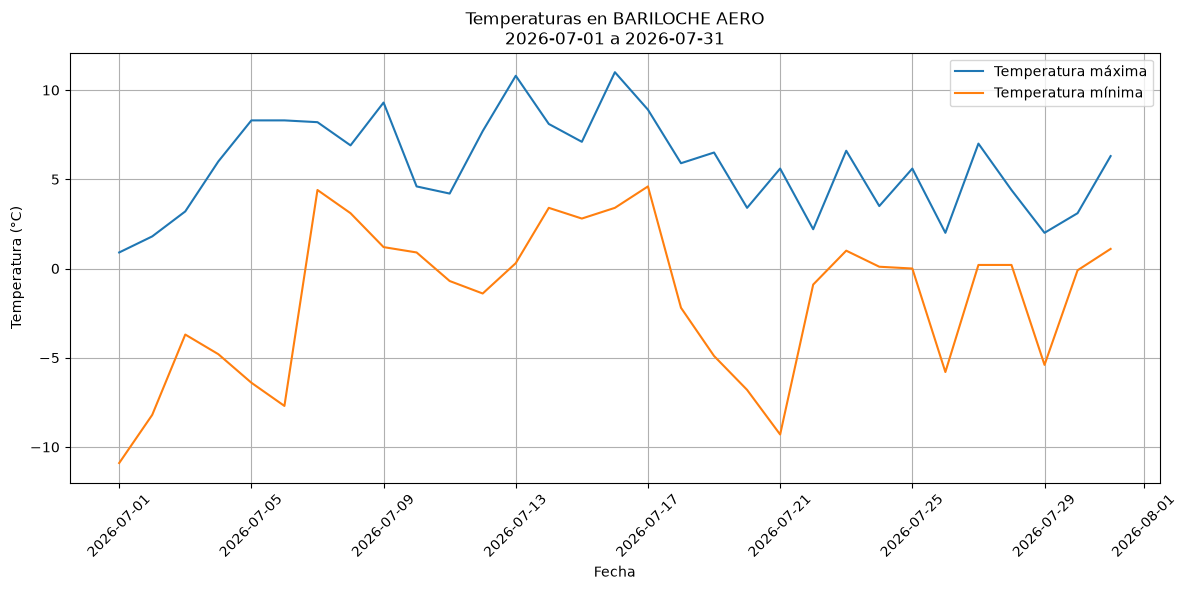

Gráfico generado correctamente para BARILOCHE AERO. Se utilizaron 31 registros entre 2026-07-01 y 2026-07-31.

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'IMAGEN_GENERADA:\n\nA continuación, te muestro el gráfico de las temperaturas máximas y mínimas registradas en la estación **BARILOCHE AERO** durante el mes de **julio de 2026**, elaborado a partir de los informes meteorológicos almacenados en la base de datos:', 'index': 0, 'extras': {'signature': 'El4KXAERTTIPgA7qoGPTp758bdJGGbb2DIklAT+egRbuYdLSlYKQ0Ama7aneF9dLe7xtkk5xCux3tmGOizz/U45663pBnVD386TVmJifo6/UPXFCbUwH+BKHnqSd+UjS'}}]

> Finished chain.
[{'type': 'text', 'text': 'IMAGEN_GENERADA:\n\nA continuación, te muestro el gráfico de las temperaturas máximas y mínimas registradas en la estación **BARILOCHE AERO** durante el mes de **julio de 2026**, elaborado a partir de los informes meteorológicos almacenados en la base de datos:', 'index': 0, 'extras': {'signature': 'El4KXAERTTIPgA7qoGPTp758bdJGGbb2DIklAT+egRbuYdLSlYKQ0Ama7aneF9dLe7xtkk5xCux3tmGOizz/U45663pBnVD386TVmJifo6/UPXFCbUwH+BKHnqSd+UjS'}}]


In [ ]:
# PRUEBA DE LA HERRAMIENTA DE GRAFICAR TEMPERATURA CON EL AGENTE
resultado = agent_executor.invoke({
    "input": "Mostrame un gráfico de la temperatura máxima y mínima de Bariloche durante julio de 2026"
})

print(resultado["output"])



> Entering new AgentExecutor chain...


c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



Invoking: `comparar_temperatura_con_normal` with `{'estacion': 'ROSARIO AERO', 'anio': 2026, 'mes': 'julio', 'tipo_temperatura': 'maxima'}`




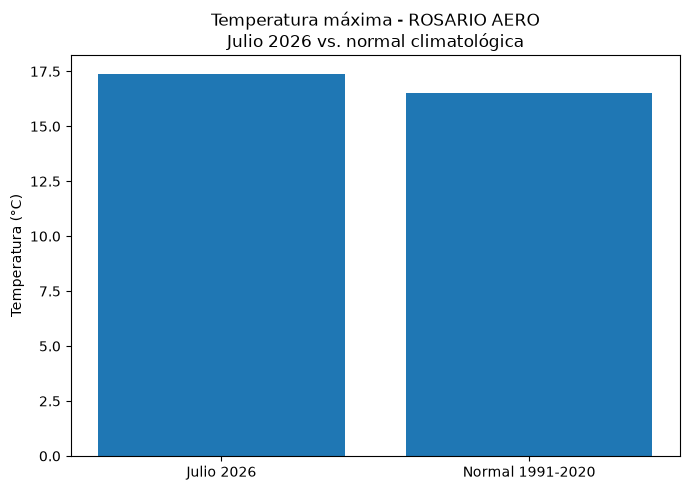

En ROSARIO AERO, la temperatura máxima promedio observada durante julio de 2026 fue de 17.4 °C. La normal climatológica 1991-2020 para ese mes es 16.5 °C. La diferencia fue de +0.9 °C, por lo que estuvo por encima de lo normal.

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Aquí tenés la comparación de la temperatura máxima de **Rosario (ROSARIO AERO)** durante **julio de 2026** frente a la normal climatológica 1991-2020, obtenida de los informes oficiales del SMN:\n\n* **Temperatura máxima promedio observada (julio 2026):** **17.4 °C**\n* **Normal climatológica (1991-2020):** **16.5 °C**\n* **Anomalía:** **+0.9 °C**\n\n**Conclusión:**\nDurante julio de 2026, la temperatura máxima media en Rosario se situó **por encima de lo normal** en casi un grado centígrado (+0.9 °C) respecto al periodo de referencia 1991-2020.', 'index': 0, 'extras': {'signature': 'El4KXAERTTIP7w+DmPG6Jf5E4jbTjV+i7IVZO/KhJvZBNna6ffTgqMhVudMqqFagDTbnqZcqhBLwnxgpU8rzX3giL0CyeoIGRrR186Fmb4wihj3GTVKly0Ur3/OkKG6T'}}]

> Finished chain.
[{'type': 'text', 'text': 'Aquí tenés la comparación de la temperatura máxima de **Rosario (ROSARIO AERO)** durante **julio de 2026** frente a la normal climatológica 1991-2020, obtenida de los informes oficiales del SMN:\n\n* **T

In [ ]:
# PRUEBA DE LA HERRAMIENTA DE COMPARAR TEMPERATURA CON EL AGENTE
resultado = agent_executor.invoke({
    "input": "Comparame la temperatura máxima de Rosario durante julio de 2026 con la normal climatológica 1991-2020"
})

print(resultado["output"])

In [ ]:
# PRUEBA DE LA HERRAMIENTA DE BUSCAR INFORMACIÓN EN LOS PDF CON EL AGENTE
resultado = agent_executor.invoke({
    "input": "Según los informes del SMN, ¿cómo fueron las precipitaciones durante mayo de 2026?"
})

print(resultado["output"])



> Entering new AgentExecutor chain...


c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



Invoking: `buscar_informacion_texto` with `{'query': 'mayo 2026 precipitaciones'}`


--- [Fuente: files\Clim-Otoño 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Otoño  2026  - Vol. XXXVIII
6
SMN
FIG. 3 – Desvío de la precipitación con respecto a la normal 
1991-2020 (mm) de marzo, abril y mayo de 2026.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 9)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
6
SMN
FIG. 5 – Frecuencia de días con lluvia.
FIG. 6 – Frecuencia de días con lluvia de primera, 
segunda y tercera década.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 5)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
2
SMN
CARACTERÍSTICAS CLIMÁTICAS 
1 - PRECIPITACIÓN
1.1 - Precipitación media
Durante el mes de mayo, una extensa zona del país que comprende al Noroeste Argentino (NOA), 
Cuyo, centro y zona central de la Patagonia presentó precipitaciones inferiores a 20 mm (Figura 1- 
isolínea negra). En varias localidades no se registraron precipitaciones, por ejemplo: 

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



Invoking: `buscar_informacion_texto` with `{'query': 'mayo 2026 precipitacion desvio normal'}`


--- [Fuente: files\Clim-Otoño 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Otoño  2026  - Vol. XXXVIII
6
SMN
FIG. 3 – Desvío de la precipitación con respecto a la normal 
1991-2020 (mm) de marzo, abril y mayo de 2026.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
3
SMN
FIG. 2 – Desvío de la precipitación con respecto a la normal 1991-2020 (mm)
• Entre Ríos: Concordia con 101.4 mm;
• Buenos Aires: Tres Arroyos con 129.1 mm, Mar del Plata con 105.1 mm y Villa Gesell con 71.3 mm;
• zona cordillerana de Neuquén: Cerro Mirador con 552.3 mm, Añihuerraqui con 396.3 mm, El Rincón 
con 393 mm, Puesto Antiao con 318.2 mm, Las Lagunas con 307.5 mm, Caviahue con 242.1 mm y 
Lago Espejo Chico con 222 mm;

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 10)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
7
SMN
FIG. 7 – Desvío de la frecu

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Según los informes del Servicio Meteorológico Nacional (SMN) para **mayo de 2026**, las características principales de las precipitaciones fueron las siguientes:\n\n* **Precipitaciones escasas en gran parte del país:** Una extensa zona que abarcó el Noroeste Argentino (NOA), Cuyo, el centro y la zona central de la Patagonia registró acumulados **inferiores a 20 mm**. En varias localidades **no se registraron precipitaciones**, tales como La Quiaca y Ceres.\n* **Máximos acumulados mensuales:** Los registros más importantes del mes se concentraron en áreas puntuales, destacándose:\n  * **Zona cordillerana de Neuquén:** Cerro Mirador (552.3 mm), Añihuerraqui (396.3 mm), El Rincón (393 mm), Puesto Antiao (318.2 mm), Las Lagunas (307.5 mm), Caviahue (242.1 mm) y Lago Espejo Chico (222 mm).\n  * **Buenos Aires:** Tres Arroyos (129.1 mm), Mar del Plata (105.1 mm) y Villa Gesell (71.3 mm).\n  * **Entre Ríos:** Concordia (101.4 mm).\n* **Eventos diarios destacados:** 

In [ ]:
# Este codigo se ocupa de formatear bien la salida

from IPython.display import Image, Markdown, display

def obtener_texto_limpio(output_data):
  # Si la salida es una lista de bloques (como en tu ejemplo)
  if isinstance(output_data, list):
    texto_completo = []
    for bloque in output_data:
      if isinstance(bloque, dict) and "text" in bloque:
        texto_completo.append(bloque["text"])
    return "\n".join(texto_completo)
  # Si ya es un string normal
  elif isinstance(output_data, str):
    return output_data
  return str(output_data)

# --- Ejecución ---
resultado = agent_executor.invoke({"input": "Como fue la precipitacion media en mayo 2026 comparada con la del otoño 2026?"})

# Extraemos el texto estructurado
output_text = obtener_texto_limpio(resultado["output"])

# 1. Verificar si hay una imagen de por medio (en respuesta o pasos intermedios)
path_imagen = None
for action, observation in resultado.get("intermediate_steps", []):
  if isinstance(observation, str) and "IMAGEN_GENERADA:" in observation:
    path_imagen = observation.split("IMAGEN_GENERADA:")[1].strip()
    break

# 2. Renderizado limpio en el Notebook
display(Markdown(output_text))

if path_imagen:
  display(Image(filename=path_imagen))

Con base en los informes del Servicio Meteorológico Nacional (**Boletín Climatológico de Otoño 2026** y **Boletín Climatológico de Mayo 2026**), a continuación se comparan las características de las precipitaciones:

* **Precipitación media estacional (Otoño 2026):**
  - Las precipitaciones acumuladas durante todo el trimestre estacional (**marzo, abril y mayo de 2026**) superaron los **400 mm** en amplias regiones del país.
  - Entre las zonas más destacadas con acumulados superiores a este valor se encuentran gran parte de **Formosa y Chaco**, el norte de **Corrientes y Santa Fe**, el sudeste de **Santiago del Estero**, el centro de **Buenos Aires**, sectores aislados de **Salta, Jujuy y Tucumán**, y la **zona cordillerana**.

* **Precipitación media mensual (Mayo 2026):**
  - Durante el mes de mayo de 2026, el comportamiento pluviométrico estuvo marcado por la escasez en gran parte del territorio nacional. Una extensa zona que abarcó el **Noroeste Argentino (NOA), Cuyo, el centro y la zona central de la Patagonia** registró acumulados **inferiores a los 20 mm**.
  - Incluso se constataron localidades **sin registro de precipitaciones** durante todo el mes (tales como *La Quiaca* y *Ceres*).
  - Por el contrario, los mayores acumulados y desvíos positivos puntuales de mayo se concentraron en áreas específicas como el sur de Buenos Aires (ej. Tres Arroyos con 129,1 mm, Mar del Plata con 105,1 mm), Entre Ríos (Concordia con 101,4 mm) y la zona cordillerana de Neuquén (Cerro Mirador con valores destacados superiores a 500 mm).

* **Comparación general:**
  - Mientras que el otoño en su conjunto (marzo-abril-mayo) acumuló volúmenes importantes y generalizados de lluvia superiores a los 400 mm en el norte, Litoral y centro, **mayo aportó condiciones notablemente más secas** en las regiones del NOA, Cuyo y Patagonia central, contrastando fuertemente con los aportes hídricos más abundantes que típicamente recibió el trimestre, limitando las lluvias significativas del mes casi exclusivamente a sectores puntuales del este, sur bonaerense y la cordillera patagónica.